In [1]:
!pip install rdkit pandas matplotlib pubchempy PyTDC

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 31.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of pytdc to determine which version is compatible with other requirements. This could take a while.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 68.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  error: subprocess-exited-with-error
  
  × Preparing metadata (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This e

In [2]:
import pubchempy as pcp
import pandas as pd

names = ["albendazole", "mebendazole", "thiabendazole", "omeprazole",
         "pantoprazole", "lansoprazole", "carbendazim", "telmisartan",
         "candesartan", "bendamustine"]

rows = []
for n in names:
    c = pcp.get_compounds(n, "name")
    if c:
        rows.append({"name": n, "smiles": c[0].isomeric_smiles})
bz = pd.DataFrame(rows)
bz

ModuleNotFoundError: No module named 'pubchempy'

In [3]:
!pip install pubchempy rdkit


  Using cached pubchempy-1.0.5-py3-none-any.whl.metadata (4.3 kB)
  Using cached rdkit-2026.9.1-cp313-cp313-manylinux_2_28_x86_64.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 108.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pubchempy]


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors

In [10]:
import pubchempy as pcp

names = ["albendazole", "mebendazole", "thiabendazole", "omeprazole",
         "pantoprazole", "lansoprazole", "carbendazim", "telmisartan",
         "candesartan", "bendamustine"]

rows = []
for n in names:
    c = pcp.get_compounds(n, "name")
    if c:
        rows.append({"name": n, "smiles": c[0].isomeric_smiles})
bz = pd.DataFrame(rows)
bz

/tmp/ipykernel_1283/1733778014.py:11: PubChemPyDeprecationWarning: isomeric_smiles is deprecated: Use smiles instead
  rows.append({"name": n, "smiles": c[0].isomeric_smiles})


,name,smiles
0,albendazole,CCCSC1=CC2=C(C=C1)N=C(N2)NC(=O)OC
1,mebendazole,COC(=O)NC1=NC2=C(N1)C=C(C=C2)C(=O)C3=CC=CC=C3
2,thiabendazole,C1=CC=C2C(=C1)NC(=N2)C3=CSC=N3
3,omeprazole,CC1=CN=C(C(=C1OC)C)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC
4,pantoprazole,COC1=C(C(=NC=C1)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC(...
5,lansoprazole,CC1=C(C=CN=C1CS(=O)C2=NC3=CC=CC=C3N2)OCC(F)(F)F
6,carbendazim,COC(=O)NC1=NC2=CC=CC=C2N1
7,telmisartan,CCCC1=NC2=C(N1CC3=CC=C(C=C3)C4=CC=CC=C4C(=O)O)...
8,candesartan,CCOC1=NC2=CC=CC(=C2N1CC3=CC=C(C=C3)C4=CC=CC=C4...
9,bendamustine,CN1C2=C(C=C(C=C2)N(CCCl)CCCl)N=C1CCCC(=O)O


In [11]:
def props(smiles):
    m = Chem.MolFromSmiles(smiles)
    if m is None:
        return pd.Series([None]*6)
    return pd.Series([
        Descriptors.MolWt(m),
        Crippen.MolLogP(m),
        Lipinski.NumHDonors(m),
        Lipinski.NumHAcceptors(m),
        rdMolDescriptors.CalcTPSA(m),
        Lipinski.NumRotatableBonds(m)])

cols = ["MW", "logP", "HBD", "HBA", "TPSA", "RotBonds"]
bz[cols] = bz["smiles"].apply(props)
bz.round(2)

,name,smiles,MW,logP,HBD,HBA,TPSA,RotBonds
0,albendazole,CCCSC1=CC2=C(C=C1)N=C(N2)NC(=O)OC,265.34,3.24,2.0,4.0,67.01,4.0
1,mebendazole,COC(=O)NC1=NC2=C(N1)C=C(C=C2)C(=O)C3=CC=CC=C3,295.30,2.97,2.0,4.0,84.08,3.0
2,thiabendazole,C1=CC=C2C(=C1)NC(=N2)C3=CSC=N3,201.25,2.69,1.0,3.0,41.57,1.0
3,omeprazole,CC1=CN=C(C(=C1OC)C)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC,345.42,2.90,1.0,5.0,77.10,5.0
4,pantoprazole,COC1=C(C(=NC=C1)CS(=O)C2=NC3=C(N2)C=C(C=C3)OC(...,383.38,2.88,1.0,6.0,86.33,7.0
5,lansoprazole,CC1=C(C=CN=C1CS(=O)C2=NC3=CC=CC=C3N2)OCC(F)(F)F,369.37,3.52,1.0,4.0,67.87,5.0
6,carbendazim,COC(=O)NC1=NC2=CC=CC=C2N1,191.19,1.74,2.0,3.0,67.01,1.0
7,telmisartan,CCCC1=NC2=C(N1CC3=CC=C(C=C3)C4=CC=CC=C4C(=O)O)...,514.63,7.26,1.0,3.0,72.94,7.0
8,candesartan,CCOC1=NC2=CC=CC(=C2N1CC3=CC=C(C=C3)C4=CC=CC=C4...,440.46,4.03,2.0,6.0,118.81,7.0
9,bendamustine,CN1C2=C(C=C(C=C2)N(CCCl)CCCl)N=C1CCCC(=O)O,358.27,3.26,1.0,3.0,58.36,9.0


In [12]:
def violations(r):
    return int(r.MW > 500) + int(r.logP > 5) + int(r.HBD > 5) + int(r.HBA > 10)

bz["Ro5_violations"] = bz.apply(violations, axis=1)
bz[["name"] + cols + ["Ro5_violations"]].round(2)

,name,MW,logP,HBD,HBA,TPSA,RotBonds,Ro5_violations
0,albendazole,265.34,3.24,2.0,4.0,67.01,4.0,0
1,mebendazole,295.30,2.97,2.0,4.0,84.08,3.0,0
2,thiabendazole,201.25,2.69,1.0,3.0,41.57,1.0,0
3,omeprazole,345.42,2.90,1.0,5.0,77.10,5.0,0
4,pantoprazole,383.38,2.88,1.0,6.0,86.33,7.0,0
5,lansoprazole,369.37,3.52,1.0,4.0,67.87,5.0,0
6,carbendazim,191.19,1.74,2.0,3.0,67.01,1.0,0
7,telmisartan,514.63,7.26,1.0,3.0,72.94,7.0,2
8,candesartan,440.46,4.03,2.0,6.0,118.81,7.0,0
9,bendamustine,358.27,3.26,1.0,3.0,58.36,9.0,0


In [13]:
ref = pd.read_csv("https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/Lipophilicity.csv")
ref = ref.rename(columns={"smiles": "Drug", "exp": "Y"})
print(ref.shape)
ref.head()

(4200, 3)


,CMPD_CHEMBLID,Y,Drug
0,CHEMBL596271,3.54,Cn1c(CN2CCN(CC2)c3ccc(Cl)cc3)nc4ccccc14
1,CHEMBL1951080,-1.18,COc1cc(OC)c(cc1NC(=O)CSCC(=O)O)S(=O)(=O)N2C(C)...
2,CHEMBL1771,3.69,COC(=O)[C@@H](N1CCc2sccc2C1)c3ccccc3Cl
3,CHEMBL234951,3.37,OC[C@H](O)CN1C(=O)C(Cc2ccccc12)NC(=O)c3cc4cc(C...
4,CHEMBL565079,3.10,Cc1cccc(C[C@H](NC(=O)c2cc(nn2C)C(C)(C)C)C(=O)N...


In [14]:
# Plot 1: molecular weight distribution
plt.figure(figsize=(6,4))
plt.hist(ref["MW"], bins=40, alpha=0.6, label="TDC reference set", density=True)
plt.hist(bz["MW"], bins=8, alpha=0.8, label="Benzimidazole drugs", density=True)
plt.xlabel("Molecular weight"); plt.ylabel("Density"); plt.legend()
plt.title("Molecular weight: benzimidazole drugs vs reference set")
plt.savefig("mw_plot.png", dpi=200, bbox_inches="tight")
plt.show()

# Plot 2: MW vs logP
plt.figure(figsize=(6,5))
plt.scatter(ref["MW"], ref["logP"], s=5, alpha=0.3, label="Reference")
plt.scatter(bz["MW"], bz["logP"], s=40, color="red", label="Benzimidazoles")
plt.axvline(500, ls="--", color="grey"); plt.axhline(5, ls="--", color="grey")
plt.xlabel("Molecular weight"); plt.ylabel("logP (calculated)"); plt.legend()
plt.title("Chemical space with Lipinski limits")
plt.savefig("mw_logp.png", dpi=200, bbox_inches="tight")
plt.show()

# Plot 3: calculated logP vs measured lipophilicity (reference set)
plt.figure(figsize=(5,5))
plt.scatter(ref["logP"], ref["Y"], s=5, alpha=0.3)
plt.xlabel("Calculated logP (RDKit)"); plt.ylabel("Measured logD (AstraZeneca)")
plt.title("Calculated vs measured lipophilicity")
plt.savefig("logp_vs_logd.png", dpi=200, bbox_inches="tight")
plt.show()

KeyError: 'MW'

<Figure size 600x400 with 0 Axes>

In [15]:
print(bz.columns.tolist())
print(ref.columns.tolist())

['name', 'smiles', 'MW', 'logP', 'HBD', 'HBA', 'TPSA', 'RotBonds', 'Ro5_violations']
['CMPD_CHEMBLID', 'Y', 'Drug']


In [16]:
ref[cols] = ref["Drug"].apply(props)
ref = ref.dropna()
ref["Ro5_violations"] = ref.apply(violations, axis=1)
print(ref.shape)
print((ref["Ro5_violations"] == 0).mean())
ref.head()

(4200, 10)
0.8185714285714286


,CMPD_CHEMBLID,Y,Drug,MW,logP,HBD,HBA,TPSA,RotBonds,Ro5_violations
0,CHEMBL596271,3.54,Cn1c(CN2CCN(CC2)c3ccc(Cl)cc3)nc4ccccc14,340.858,3.5489,0.0,3.0,24.30,3.0,0
1,CHEMBL1951080,-1.18,COc1cc(OC)c(cc1NC(=O)CSCC(=O)O)S(=O)(=O)N2C(C)...,494.591,2.9901,2.0,7.0,122.24,9.0,0
2,CHEMBL1771,3.69,COC(=O)[C@@H](N1CCc2sccc2C1)c3ccccc3Cl,321.829,3.6739,0.0,4.0,29.54,3.0,0
3,CHEMBL234951,3.37,OC[C@H](O)CN1C(=O)C(Cc2ccccc12)NC(=O)c3cc4cc(C...,419.890,1.9237,4.0,5.0,105.66,5.0,0
4,CHEMBL565079,3.10,Cc1cccc(C[C@H](NC(=O)c2cc(nn2C)C(C)(C)C)C(=O)N...,381.480,2.0069,2.0,4.0,99.81,6.0,0


In [17]:
print(bz[["name","MW","logP","HBD","HBA","Ro5_violations"]].round(2).to_string())
print()
print("Reference set size:", len(ref))
print("Reference: fraction with 0 violations:", round((ref["Ro5_violations"]==0).mean(), 3))
print("Benzimidazoles: fraction with 0 violations:", round((bz["Ro5_violations"]==0).mean(), 3))
print("Median MW  - reference:", round(ref["MW"].median(),1), " benzimidazoles:", round(bz["MW"].median(),1))
print("Median logP - reference:", round(ref["logP"].median(),2), " benzimidazoles:", round(bz["logP"].median(),2))
print("Correlation, calculated logP vs measured logD:", round(ref["logP"].corr(ref["Y"]),2))

            name      MW  logP  HBD  HBA  Ro5_violations
0    albendazole  265.34  3.24  2.0  4.0               0
1    mebendazole  295.30  2.97  2.0  4.0               0
2  thiabendazole  201.25  2.69  1.0  3.0               0
3     omeprazole  345.42  2.90  1.0  5.0               0
4   pantoprazole  383.38  2.88  1.0  6.0               0
5   lansoprazole  369.37  3.52  1.0  4.0               0
6    carbendazim  191.19  1.74  2.0  3.0               0
7    telmisartan  514.63  7.26  1.0  3.0               2
8    candesartan  440.46  4.03  2.0  6.0               0
9   bendamustine  358.27  3.26  1.0  3.0               0

Reference set size: 4200
Reference: fraction with 0 violations: 0.819
Benzimidazoles: fraction with 0 violations: 0.9
Median MW  - reference: 388.4  benzimidazoles: 351.8
Median logP - reference: 3.28  benzimidazoles: 3.11
Correlation, calculated logP vs measured logD: 0.42


In [18]:
!ls *.png


ls: cannot access '*.png': No such file or directory


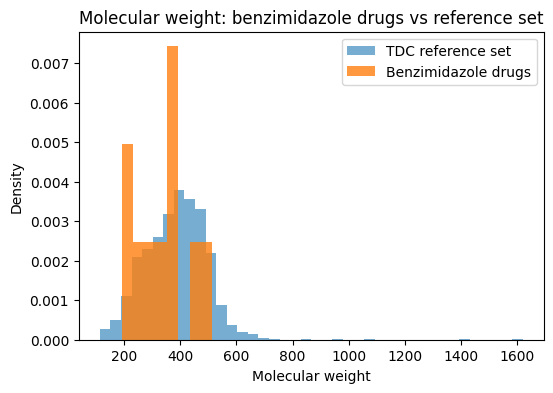

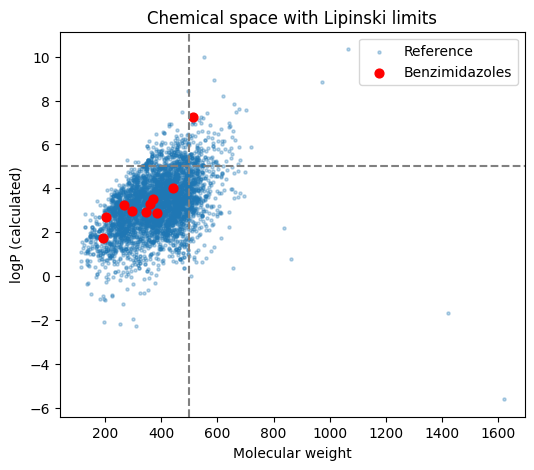

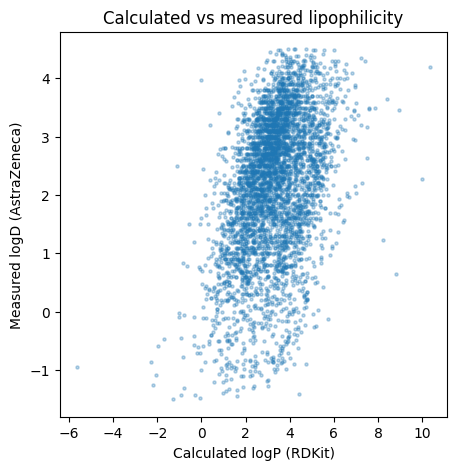

In [19]:
# Plot 1: molecular weight distribution
plt.figure(figsize=(6,4))
plt.hist(ref["MW"], bins=40, alpha=0.6, label="TDC reference set", density=True)
plt.hist(bz["MW"], bins=8, alpha=0.8, label="Benzimidazole drugs", density=True)
plt.xlabel("Molecular weight"); plt.ylabel("Density"); plt.legend()
plt.title("Molecular weight: benzimidazole drugs vs reference set")
plt.savefig("mw_plot.png", dpi=200, bbox_inches="tight")
plt.show()

# Plot 2: MW vs logP
plt.figure(figsize=(6,5))
plt.scatter(ref["MW"], ref["logP"], s=5, alpha=0.3, label="Reference")
plt.scatter(bz["MW"], bz["logP"], s=40, color="red", label="Benzimidazoles")
plt.axvline(500, ls="--", color="grey"); plt.axhline(5, ls="--", color="grey")
plt.xlabel("Molecular weight"); plt.ylabel("logP (calculated)"); plt.legend()
plt.title("Chemical space with Lipinski limits")
plt.savefig("mw_logp.png", dpi=200, bbox_inches="tight")
plt.show()

# Plot 3: calculated logP vs measured lipophilicity (reference set)
plt.figure(figsize=(5,5))
plt.scatter(ref["logP"], ref["Y"], s=5, alpha=0.3)
plt.xlabel("Calculated logP (RDKit)"); plt.ylabel("Measured logD (AstraZeneca)")
plt.title("Calculated vs measured lipophilicity")
plt.savefig("logp_vs_logd.png", dpi=200, bbox_inches="tight")
plt.show()

In [21]:
bz.to_csv("benzimidazole_properties.csv", index=False)

In [22]:
!ls *.png

logp_vs_logd.png  mw_logp.png  mw_plot.png


In [23]:
from google.colab import files
for f in ["mw_plot.png", "mw_logp.png", "logp_vs_logd.png", "benzimidazole_properties.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>